In [1]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# 1. Paragraph
text = """I love technology because it makes life easier.
Artificial intelligence helps people solve problems.
I enjoy learning about AI and creating new applications.
Technology is changing the world every day.
I want to build useful AI projects in the future."""

# 2. Lowercase and remove punctuation
text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', text)
print("Clean text:", clean_text)

# 3. Tokenize sentences and words
print("\nSentences:", sent_tokenize(text))

print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(text))

# 4. Remove stopwords
words = word_tokenize(clean_text)
stop_words = stopwords.words('english')

filtered_words = []
for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("\nWords after removing stopwords:", filtered_words)

# 5. Word frequency
freq = FreqDist(filtered_words)
print("\nWord frequency:", freq)
print("\nFrequency of each word:")
for word, count in freq.items():
    print(word, ":", count)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Clean text: i love technology because it makes life easier
artificial intelligence helps people solve problems
i enjoy learning about ai and creating new applications
technology is changing the world every day
i want to build useful ai projects in the future

Sentences: ['i love technology because it makes life easier.', 'artificial intelligence helps people solve problems.', 'i enjoy learning about ai and creating new applications.', 'technology is changing the world every day.', 'i want to build useful ai projects in the future.']

Using split(): ['i', 'love', 'technology', 'because', 'it', 'makes', 'life', 'easier', 'artificial', 'intelligence', 'helps', 'people', 'solve', 'problems', 'i', 'enjoy', 'learning', 'about', 'ai', 'and', 'creating', 'new', 'applications', 'technology', 'is', 'changing', 'the', 'world', 'every', 'day', 'i', 'want', 'to', 'build', 'useful', 'ai', 'projects', 'in', 'the', 'future']

Using word_tokenize(): ['i', 'love', 'technology', 'because', 'it', 'makes',

In [2]:

import re
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Same paragraph from Q1
text = """I love technology because it makes life easier.
Artificial intelligence helps people solve problems.
I enjoy learning about AI and creating new applications.
Technology is changing the world every day.
I want to build useful AI projects in the future."""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Words:", words)

# 2. Remove stopwords
stop_words = stopwords.words('english')
filtered_words = []

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("\nAfter removing stopwords:", filtered_words)

# 3. Stemming
ps = PorterStemmer()
stemmed_words = []

for word in filtered_words:
    stemmed_words.append(ps.stem(word))

print("\nStemmed words:", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemma_words = []

for word in filtered_words:
    lemma_words.append(lemmatizer.lemmatize(word))

print("\nLemmatized words:", lemma_words)

# 5. Compare outputs
print("\nComparison:")
for i in range(len(filtered_words)):
    print(filtered_words[i], "-> Stem:", stemmed_words[i],
          "| Lemma:", lemma_words[i])


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Words: ['i', 'love', 'technology', 'because', 'it', 'makes', 'life', 'easier', 'artificial', 'intelligence', 'helps', 'people', 'solve', 'problems', 'i', 'enjoy', 'learning', 'about', 'ai', 'and', 'creating', 'new', 'applications', 'technology', 'is', 'changing', 'the', 'world', 'every', 'day', 'i', 'want', 'to', 'build', 'useful', 'ai', 'projects', 'in', 'the', 'future']

After removing stopwords: ['love', 'technology', 'makes', 'life', 'easier', 'artificial', 'intelligence', 'helps', 'people', 'solve', 'problems', 'enjoy', 'learning', 'ai', 'creating', 'new', 'applications', 'technology', 'changing', 'world', 'every', 'day', 'want', 'build', 'useful', 'ai', 'projects', 'future']

Stemmed words: ['love', 'technolog', 'make', 'life', 'easier', 'artifici', 'intellig', 'help', 'peopl', 'solv', 'problem', 'enjoy', 'learn', 'ai', 'creat', 'new', 'applic', 'technolog', 'chang', 'world', 'everi', 'day', 'want', 'build', 'use', 'ai', 'project', 'futur']

Lemmatized words: ['love', 'technology

In [3]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Three short texts
texts = [
    "The phone has an excellent camera and great battery life",
    "The laptop is fast and has an excellent screen",
    "The camera takes great photos and the battery lasts long"
]

# 2. Bag of Words using CountVectorizer
cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(bow.toarray())
print("Words:", cv.get_feature_names_out())

# 3. TF-IDF scores
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)

print("\nTF-IDF Scores:")
print(tfidf_matrix.toarray())

# 4. Top 3 keywords from each text
features = tfidf.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray()[0]
    top_indices = scores.argsort()[-3:][::-1]

    print("\nText", i + 1, ":", text)
    print("Top 3 keywords:")

    for index in top_indices:
        print(features[index], ":", round(scores[index], 3))


Bag of Words:
[[1 1 1 1 1 0 1 1 0 0 0 1 0 1 0 0 0 1]
 [1 1 0 0 1 1 0 1 1 1 0 0 0 0 0 1 0 1]
 [0 1 1 1 0 0 1 0 0 0 1 0 1 0 1 0 1 2]]
Words: ['an' 'and' 'battery' 'camera' 'excellent' 'fast' 'great' 'has' 'is'
 'laptop' 'lasts' 'life' 'long' 'phone' 'photos' 'screen' 'takes' 'the']

TF-IDF Scores:
[[0.30622451 0.23781065 0.30622451 0.30622451 0.30622451 0.
  0.30622451 0.30622451 0.         0.         0.         0.40264842
  0.         0.40264842 0.         0.         0.         0.23781065]
 [0.29985557 0.2328646  0.         0.         0.29985557 0.39427404
  0.         0.29985557 0.39427404 0.39427404 0.         0.
  0.         0.         0.         0.39427404 0.         0.2328646 ]
 [0.         0.21596023 0.27808812 0.27808812 0.         0.
  0.27808812 0.         0.         0.         0.36565246 0.
  0.36565246 0.         0.36565246 0.         0.36565246 0.43192047]]

Text 1 : The phone has an excellent camera and great battery life
Top 3 keywords:
life : 0.403
phone : 0.403
camera : 

In [4]:

import re
import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('punkt')
nltk.download('punkt_tab')

# 1. Two short texts
text1 = """Artificial intelligence enables machines to learn from data.
AI helps solve problems and make predictions.
It is used in healthcare, education, and robotics.
Machine learning is an important part of AI."""

text2 = """Blockchain stores information in secure digital blocks.
It helps maintain transparent and decentralized records.
Blockchain is used in cryptocurrency and banking.
Cryptocurrency transactions are recorded on a blockchain."""

# 2. Preprocess and tokenize
text1 = re.sub(r'[^\w\s]', '', text1.lower())
text2 = re.sub(r'[^\w\s]', '', text2.lower())

words1 = nltk.word_tokenize(text1)
words2 = nltk.word_tokenize(text2)

print("AI tokens:", words1)
print("\nBlockchain tokens:", words2)

# 3a. Jaccard Similarity
set1 = set(words1)
set2 = set(words2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", round(jaccard, 3))

# 3b. Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(vectors[0:1], vectors[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 3))

# 4. Comparison
print("\nAnalysis:")
print("Jaccard measures the overlap between unique words.")
print("Cosine measures similarity using TF-IDF word importance.")


AI tokens: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'helps', 'solve', 'problems', 'and', 'make', 'predictions', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'robotics', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'ai']

Blockchain tokens: ['blockchain', 'stores', 'information', 'in', 'secure', 'digital', 'blocks', 'it', 'helps', 'maintain', 'transparent', 'and', 'decentralized', 'records', 'blockchain', 'is', 'used', 'in', 'cryptocurrency', 'and', 'banking', 'cryptocurrency', 'transactions', 'are', 'recorded', 'on', 'a', 'blockchain']

Jaccard Similarity: 0.133
Cosine Similarity: 0.174

Analysis:
Jaccard measures the overlap between unique words.
Cosine measures similarity using TF-IDF word importance.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!



Review: This phone is amazing and the camera quality is excellent.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: I love this product. It works perfectly and is worth the money.
Polarity: 0.6
Subjectivity: 0.57
Sentiment: Positive

Review: The battery is poor and the phone is very slow.
Polarity: -0.4
Subjectivity: 0.56
Sentiment: Negative

Review: The product is terrible and I am disappointed.
Polarity: -0.88
Subjectivity: 0.88
Sentiment: Negative

Review: The phone is okay and works normally.
Polarity: 0.33
Subjectivity: 0.57
Sentiment: Positive

Review: The product is average and nothing special.
Polarity: 0.1
Subjectivity: 0.49
Sentiment: Positive


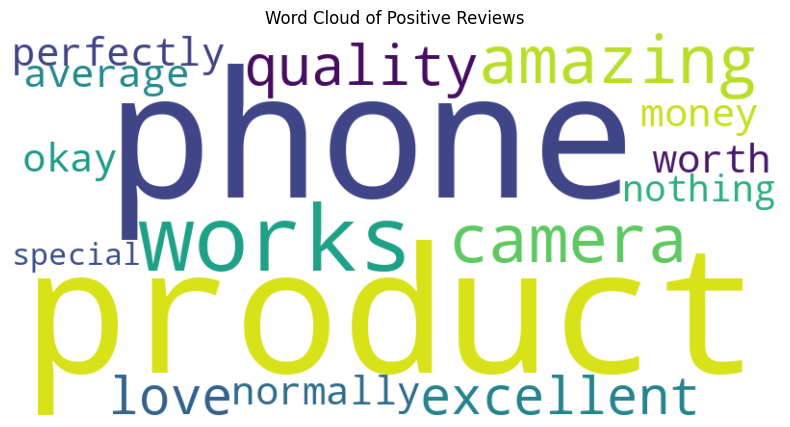

In [5]:

# Install required libraries
!pip install textblob wordcloud

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Write product reviews
reviews = [
    "This phone is amazing and the camera quality is excellent.",
    "I love this product. It works perfectly and is worth the money.",
    "The battery is poor and the phone is very slow.",
    "The product is terrible and I am disappointed.",
    "The phone is okay and works normally.",
    "The product is average and nothing special."
]

positive_reviews = []

# 2. Find polarity, subjectivity and classify reviews
for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)

# 3. Create a word cloud from positive reviews
text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [7]:

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Artificial intelligence is changing the world.
Machines can learn from data and solve complex problems.
AI helps doctors detect diseases and helps students learn better.
Machine learning allows computers to identify patterns.
Deep learning uses neural networks to process information.
AI can recognize images, understand language, and generate text.
Robots use artificial intelligence to perform different tasks.
Technology makes our lives easier and more productive.
However, AI should be used responsibly and safely.
The future of artificial intelligence is exciting.
Researchers continue to develop intelligent systems.
These systems can help people in education, healthcare, and science.
AI can support creativity and improve decision making.
Learning about technology helps us prepare for the future.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.lower().split('.'):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        sequences.append(tokens[:i + 1])

# Pad sequences
max_length = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_length, padding='pre')

# Input and output
X = sequences[:, :-1]
y = sequences[:, -1]

# 3. Build an LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=X.shape[1]),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# 4. Train the model
model.fit(X, y, epochs=100, verbose=0)
print("Model training completed!")

# 5. Generate text using a seed word

def generate_text(seed, next_words=10):
    for _ in range(next_words):
        tokens = tokenizer.texts_to_sequences([seed])[0]

        # Pad the token sequence directly
        tokens = pad_sequences(
            [tokens],
            maxlen=X.shape[1],
            padding='pre'
        )

        prediction = model.predict(tokens, verbose=0)
        predicted_id = np.argmax(prediction[0])

        # Find the predicted word
        predicted_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                predicted_word = word
                break

        if predicted_word == "":
            break

        seed += " " + predicted_word

    return seed

# Generate text
print("Generated text:")
print(generate_text("artificial", 10))
print(generate_text("technology", 10))
print(generate_text("machines", 10))


Model training completed!
Generated text:
artificial intelligence intelligence to to perform tasks tasks tasks tasks tasks
technology can can be and and decision making problems better better
machines can can from easier and and complex problems problems better
